In [1]:
import torch

import torch.utils.data

import pandas as pd
import scanpy as sc
import squidpy as sq

from pathlib import Path

from gctsvg import visualization
from gctsvg.preprocessing import common, singlecell, kidneycancer
from gctsvg.model.classifier import ClassifierDriver

/opt/conda/envs/ctSVG/lib/python3.12/site-packages/dask/dataframe/_pyarrow_compat.py:15: FutureWarning: Minimal version of pyarrow will soon be increased to 14.0.1. You are using 13.0.0. Please consider upgrading.
  warnings.warn(
/opt/conda/envs/ctSVG/lib/python3.12/site-packages/anndata/utils.py:434: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)


In [2]:
data_dir = Path('data_repo/Human Kidney Cancer')
# read scRNA data
adata_sc = sc.read(data_dir / 'RCC_upload_final_raw_counts.h5ad')
adata_sc.var_names_make_unique()

In [3]:
# Extract patient data
patient_id='PD47171'
adata_sc = kidneycancer.extract_sc_patient_data(adata_sc, patient_id)
# common.preprocess(adata_sc)
cell_types, n_classes = singlecell.get_cell_types(adata_sc)

In [4]:
n_feats = adata_sc.n_vars
device = torch.device('cuda:1' if torch.cuda.is_available() else 'cpu')

In [5]:
cell_types

['B-cell',
 'EC',
 'Epi_non-PT',
 'Epi_PT',
 'Fibro',
 'Mast',
 'Myeloid',
 'NK',
 'Plasma',
 'RCC',
 'T-cell',
 'pDC']

In [6]:
n_classes

12

In [7]:
n_feats

19736

In [8]:
dataset = singlecell.create_classifier_dataset(adata_sc, device=device)
dataset

In [9]:
dataset[2][0].shape, dataset[2][1].shape

(torch.Size([19736]), torch.Size([]))

In [10]:
driver = ClassifierDriver(n_feats, n_classes)

tensor([19736, 14805,  9874,  4943], dtype=torch.int32)


In [11]:
num_epochs=50
batch_size=4096

In [12]:
adata_sc.X

<Compressed Sparse Column sparse matrix of dtype 'float32'
	with 46003595 stored elements and shape (36110, 19736)>

In [13]:
losses = driver.train(dataset, num_epochs, batch_size)

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/9 [00:00<?, ?it/s]

  0%|          | 0/9 [00:00<?, ?it/s]

  0%|          | 0/9 [00:00<?, ?it/s]

  0%|          | 0/9 [00:00<?, ?it/s]

  0%|          | 0/9 [00:00<?, ?it/s]

... (41 outputs left out)

  0%|          | 0/9 [00:00<?, ?it/s]

  0%|          | 0/9 [00:00<?, ?it/s]

  0%|          | 0/9 [00:00<?, ?it/s]

  0%|          | 0/9 [00:00<?, ?it/s]

In [14]:
classifier = driver.get_classifier()

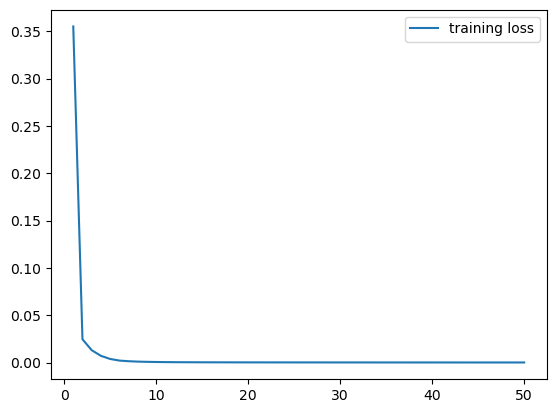

In [15]:
visualization.show_training_curve(range(1,num_epochs + 1), [losses], ["training loss"])

In [16]:
classifier

Classifier(
  (backbone_fc): Sequential(
    (0): Linear(in_features=19736, out_features=14805, bias=True)
    (1): BatchNorm1d(14805, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): PReLU(num_parameters=14805)
    (3): Linear(in_features=14805, out_features=9874, bias=True)
    (4): BatchNorm1d(9874, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): PReLU(num_parameters=9874)
    (6): Linear(in_features=9874, out_features=4943, bias=True)
    (7): BatchNorm1d(4943, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (8): PReLU(num_parameters=4943)
  )
  (out_fc): Linear(in_features=4943, out_features=12, bias=True)
)